In [1]:
!pip install torch torchvision matplotlib pandas psutil -q

import torch
import torchvision
import time
import psutil
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

print("PyTorch Version:", torch.__version__)
print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Enable GPU in Runtime settings.")

PyTorch Version: 2.14.1+cpu
GPU Available: False
GPU not available. Enable GPU in Runtime settings.


In [2]:
import torch.nn as nn

class CNNModel(nn.Module):
    def __init__(self):
        super(CNNModel, self).__init__()

        self.network = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Flatten(),
            nn.Linear(64 * 56 * 56, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.network(x)

model = CNNModel()

if torch.cuda.is_available():
    model = model.cuda()

model.eval()

print("CNN Model Created Successfully!")
print(model)

CNN Model Created Successfully!
CNNModel(
  (network): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Flatten(start_dim=1, end_dim=-1)
    (7): Linear(in_features=200704, out_features=128, bias=True)
    (8): ReLU()
    (9): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [3]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)

input_data = torch.randn(32, 3, 224, 224).to(device)

# Warm-up
with torch.no_grad():
    for _ in range(10):
        model(input_data)

if device.type == "cuda":
    torch.cuda.synchronize()

# Measure inference
start_time = time.time()

with torch.no_grad():
    for _ in range(100):
        output = model(input_data)

if device.type == "cuda":
    torch.cuda.synchronize()

end_time = time.time()

total_time = end_time - start_time
average_time = (total_time / 100) * 1000

print("Device:", device)
print("Total Inference Time:", round(total_time, 4), "seconds")
print("Average Inference Time:", round(average_time, 4), "ms")
print("Output Shape:", output.shape)

Device: cpu
Total Inference Time: 183.4671 seconds
Average Inference Time: 1834.6706 ms
Output Shape: torch.Size([32, 10])


In [4]:
cpu_usage = psutil.cpu_percent(interval=1)
ram_usage = psutil.virtual_memory().percent

if torch.cuda.is_available():
    gpu_memory = torch.cuda.memory_allocated() / (1024 ** 2)
    gpu_reserved = torch.cuda.memory_reserved() / (1024 ** 2)
else:
    gpu_memory = 0
    gpu_reserved = 0

print("----- SYSTEM BOTTLENECK ANALYSIS -----")

print("CPU Usage:", cpu_usage, "%")
print("RAM Usage:", ram_usage, "%")
print("GPU Memory Allocated:", round(gpu_memory, 2), "MB")
print("GPU Memory Reserved:", round(gpu_reserved, 2), "MB")
print("Inference Latency:", round(average_time, 4), "ms")

if cpu_usage > 80:
    print("Possible CPU Bottleneck")
else:
    print("No high CPU utilization detected")

if ram_usage > 80:
    print("Possible RAM Bottleneck")
else:
    print("No high RAM utilization detected")

if device.type == "cuda" and gpu_memory > 0:
    print("GPU Memory Usage Detected")

----- SYSTEM BOTTLENECK ANALYSIS -----
CPU Usage: 3.0 %
RAM Usage: 12.5 %
GPU Memory Allocated: 0 MB
GPU Memory Reserved: 0 MB
Inference Latency: 1834.6706 ms
No high CPU utilization detected
No high RAM utilization detected


In [5]:
batch_sizes = [1, 8, 16, 32, 64]
results = []

for batch in batch_sizes:

    x = torch.randn(batch, 3, 224, 224).to(device)

    with torch.no_grad():
        for _ in range(5):
            model(x)

    if device.type == "cuda":
        torch.cuda.synchronize()

    start = time.time()

    with torch.no_grad():
        for _ in range(20):
            model(x)

    if device.type == "cuda":
        torch.cuda.synchronize()

    end = time.time()

    latency = ((end - start) / 20) * 1000

    results.append({
        "Batch Size": batch,
        "Inference Time (ms)": latency,
        "Time Per Image (ms)": latency / batch
    })

df = pd.DataFrame(results)
print(df.to_string(index=False))

 Batch Size  Inference Time (ms)  Time Per Image (ms)
          1            62.239969            62.239969
          8           392.669630            49.083704
         16           912.521887            57.032618
         32          1811.718750            56.616211
         64          3642.576265            56.915254


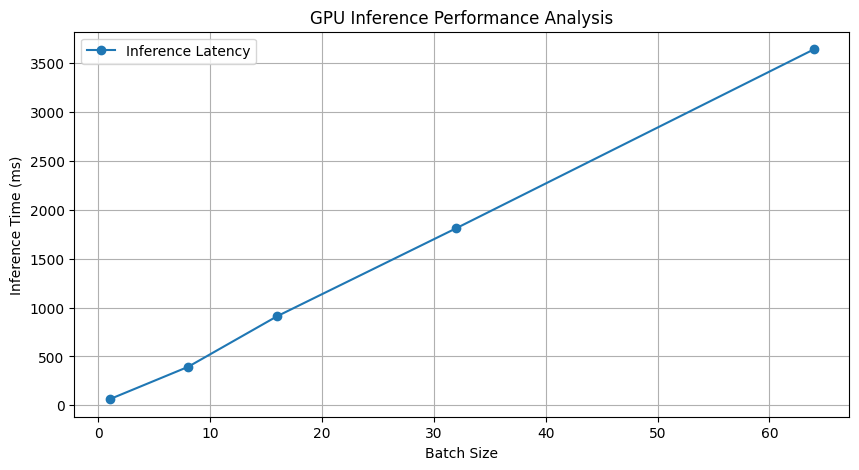

In [6]:
plt.figure(figsize=(10, 5))

plt.plot(
    df["Batch Size"],
    df["Inference Time (ms)"],
    marker='o',
    label="Inference Latency"
)

plt.xlabel("Batch Size")
plt.ylabel("Inference Time (ms)")
plt.title("GPU Inference Performance Analysis")
plt.grid(True)
plt.legend()
plt.show()

In [7]:
print("\n========== FINAL PROJECT REPORT ==========")

print("Project: GPU Inference Execution Path")
print("Execution Device:", device)
print("GPU Available:", torch.cuda.is_available())

print("\nPerformance Results:")
print(df)

print("\nSystem Analysis:")
print("CPU Usage:", cpu_usage, "%")
print("RAM Usage:", ram_usage, "%")
print("GPU Memory:", round(gpu_memory, 2), "MB")

print("\nConclusion:")
print("GPU inference performance was measured.")
print("Different batch sizes were tested.")
print("CPU, RAM and GPU memory usage were monitored.")
print("System-level performance bottlenecks were analyzed.")


========== FINAL PROJECT REPORT ==========
Project: GPU Inference Execution Path
Execution Device: cpu
GPU Available: False

Performance Results:
   Batch Size  Inference Time (ms)  Time Per Image (ms)
0           1            62.239969            62.239969
1           8           392.669630            49.083704
2          16           912.521887            57.032618
3          32          1811.718750            56.616211
4          64          3642.576265            56.915254

System Analysis:
CPU Usage: 3.0 %
RAM Usage: 12.5 %
GPU Memory: 0 MB

Conclusion:
GPU inference performance was measured.
Different batch sizes were tested.
CPU, RAM and GPU memory usage were monitored.
System-level performance bottlenecks were analyzed.
